# MSCS 634: Advanced Big Data and Data Mining
## Lab 2: Classification Using KNN and RNN Algorithms

**Name:** Navya Katta  
**Assignment:** Lab 2 – Classification Using KNN and RNN Algorithms

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

## Loading the dataset

In [5]:
# Load the Wine dataset
wine = load_wine()
# Features and target
X = wine.data
y = wine.target
print("Dataset shape:", X.shape)
print("Feature names:")
print(wine.feature_names)
print("\nTarget classes:")
print(wine.target_names)

Dataset shape: (178, 13)
Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target classes:
['class_0' 'class_1' 'class_2']


In [6]:
# Converting dataset into a DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)
# Target column
df["target"] = y
# Display first five rows
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Basic Data Exploration

In [7]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [12]:
# Display descriptive statistics
df.describe()
# Class distribution
print(df["target"].value_counts().sort_index())
#Class distribution with class names
class_distribution = pd.Series(y).value_counts().sort_index()
for class_id, count in class_distribution.items():
    print(f"{wine.target_names[class_id]}: {count}")

target
0    59
1    71
2    48
Name: count, dtype: int64
class_0: 59
class_1: 71
class_2: 48


## Splitting into 80% Training and 20% Testing

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42,stratify=y)
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (142, 13)
Testing set size: (36, 13)


## Implement KNN

In [15]:
k_values = [1, 5, 11, 15, 21]
knn_accuracies = []
for k in k_values:
    # Creating KNN classifier
    knn = KNeighborsClassifier(n_neighbors=k)
    # Train model
    knn.fit(X_train, y_train)
    # Make predictions
    y_pred = knn.predict(X_test)
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    knn_accuracies.append(accuracy)
    print(f"k = {k}, Accuracy = {accuracy:.4f}")

k = 1, Accuracy = 0.7778
k = 5, Accuracy = 0.8056
k = 11, Accuracy = 0.8056
k = 15, Accuracy = 0.8056
k = 21, Accuracy = 0.8056


In [16]:
knn_results = pd.DataFrame({"K Value": k_values,"Accuracy": knn_accuracies})
knn_results

,K Value,Accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


## Implement RNN

In [17]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_accuracies = []
for radius in radius_values:
    # Create Radius Neighbors classifier
    rnn = RadiusNeighborsClassifier(radius=radius,outlier_label="most_frequent")
    # Train model
    rnn.fit(X_train, y_train)
    # Make predictions
    y_pred = rnn.predict(X_test)
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    rnn_accuracies.append(accuracy)
    print(f"Radius = {radius}, Accuracy = {accuracy:.4f}")

Radius = 350, Accuracy = 0.7222
Radius = 400, Accuracy = 0.6944
Radius = 450, Accuracy = 0.6944
Radius = 500, Accuracy = 0.6944
Radius = 550, Accuracy = 0.6667
Radius = 600, Accuracy = 0.6667


In [18]:
rnn_results = pd.DataFrame({"Radius": radius_values,"Accuracy": rnn_accuracies})
rnn_results

,Radius,Accuracy
0,350,0.722222
1,400,0.694444
2,450,0.694444
3,500,0.694444
4,550,0.666667
5,600,0.666667


## Plot of KNN Accuracy

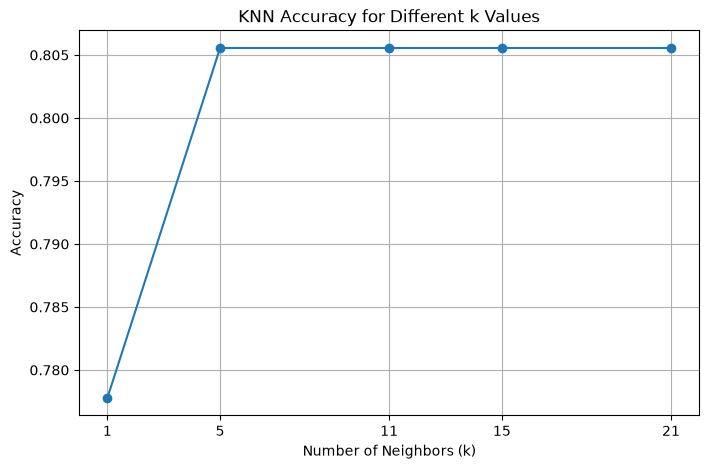

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, knn_accuracies, marker="o")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different k Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()

## Plot of RNN Accuracy

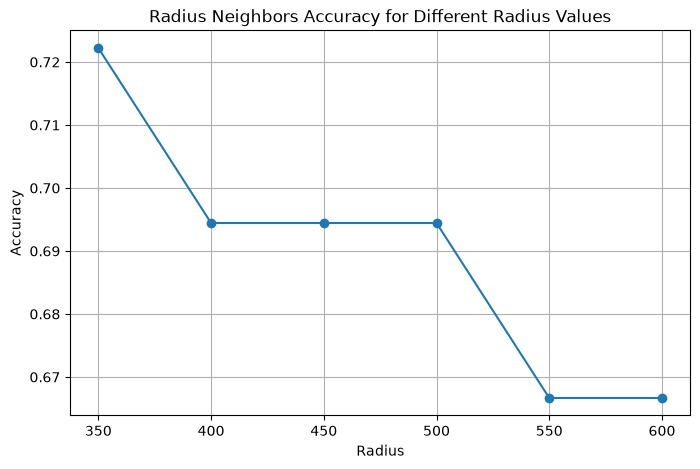

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(radius_values, rnn_accuracies, marker="o")
plt.xlabel("Radius")
plt.ylabel("Accuracy")
plt.title("Radius Neighbors Accuracy for Different Radius Values")
plt.xticks(radius_values)
plt.grid(True)
plt.show()

## Observing the Best Parameters

In [22]:
best_k_index = np.argmax(knn_accuracies)
best_radius_index = np.argmax(rnn_accuracies)
print("Best KNN Result:")
print(f"k = {k_values[best_k_index]}")
print(f"Accuracy = {knn_accuracies[best_k_index]:.2%}")
print("\nBest RNN Result:")
print(f"Radius = {radius_values[best_radius_index]}")
print(f"Accuracy = {rnn_accuracies[best_radius_index]:.2%}")

Best KNN Result:
k = 5
Accuracy = 80.56%

Best RNN Result:
Radius = 350
Accuracy = 72.22%


## Comparison and Observations

The results show that K-Nearest Neighbors (KNN) performed better than Radius Neighbors (RNN) for the tested parameter values. The highest KNN accuracy was **80.56%**, achieved at **k = 5**. For the Radius Neighbors classifier, the highest accuracy was **72.22% at radius = 350**. As the radius increased, the accuracy gradually decreased. Radius values of 400, 450, and 500 achieved approximately **69.44%**, while radius values of 550 and 600 achieved approximately **66.67%**. This suggests that increasing the radius included more distant observations that did not improve classification performance.

Overall, **KNN achieved a higher maximum test accuracy (80.56%) than RNN (72.22%)** in this experiment. KNN may be preferable when classification should be based on a fixed number of nearest observations. RNN may be useful when observations within a specific distance are more meaningful and the number of neighbors is allowed to vary. So, the result shows that selecting appropriate parameter values is important for improving the performance of distance-based classification models.